<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/01_Network_Intrusion_Detection/QBoost_IoTAttackDetection_Barletta2023.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Qboost (QUBO annealing) for IoT attack detection: Barletta et al. (2023) step by step

This notebook re-implements, runs and checks the method of

> Vita Santa Barletta, Danilo Caivano, Mirko De Vincentiis, Alessio Magri and Antonio Piccinno,
> "Quantum Optimization for IoT Security Detection", in V. Julian et al. (eds.), *Ambient Intelligence - Software and
> Applications, ISAmI 2022*, Lecture Notes in Networks and Systems 603, pp. 187-196, Springer, 2023.
> DOI 10.1007/978-3-031-22356-3_18

The paper publishes no code; it uses the open-source `qboost` example of D-Wave and the D-Wave Leap cloud service. Everything
below is written from the ten-page description.

**What the notebook does.** It downloads the *ToN_IoT* "IoT Fridge" telemetry file (the dataset the paper uses),
builds a balanced sample of attack and normal readings, trains a pool of decision stumps (the weak classifiers),
turns "which stumps should vote?" into a QUBO (quadratic unconstrained binary optimisation) problem, solves it with a
**simulated annealer written here** (checked against exact enumeration of all $2^{20}$ subsets), and compares the
resulting Qboost classifier with the paper's baseline, scikit-learn's `SVC`, on accuracy and prediction time. A small
**exact state-vector simulation of quantum annealing** (transverse-field Ising Hamiltonian, 10 stumps) shows what the D-Wave
processor does to such a QUBO. No D-Wave hardware, account or package is used.

**How to run it.** Open in Colab (badge above), choose a CPU runtime and use *Runtime -> Run all*. Nothing needs to be
installed (numpy, pandas, scikit-learn, matplotlib and `huggingface_hub` ship with Colab). `FAST_MODE = True` runs
five of the paper's sample sizes with two seeds in a few minutes; `FAST_MODE = False` runs all thirteen sample sizes that
the public file can supply with five seeds plus the ablations (about 30 minutes on a laptop CPU; 29 minutes in the reference run).

**What you get at the end.** The paper's Table 3 next to the notebook's numbers with a verdict per claim, a re-drawn
Fig. 6 (time versus sample size), the confusion matrix of the paper's Table 2, and an honest explanation of *why*
the paper's accuracy is 1.00: the label is encoded in trailing blanks of the text column `temp_condition`, not in the
temperature, so the quantum optimiser is not what makes the task easy.

## The paper in one page

**Problem.** Detect attacks in a smart-home IoT network quickly. The paper argues that quantum annealing could shorten the
time needed to classify readings.

**Decision.** Binary: *normal* (label 0) versus *attack* (label 1). The dataset also names the attack type (ddos,
backdoor, injection, password, ransomware, xss) but the paper does not use it.

**Method (Section 4, Fig. 3).** *Qboost* (Neven et al. 2008, 2012): a boosting scheme in which a set of $K$ weak classifiers
$h_i(x)\in\{-1,+1\}$ is combined as $\mathrm{sign}\big(\sum_i w_i h_i(x)\big)$ with **binary** weights $w_i\in\{0,1\}$. Choosing the
weights that minimise the squared error plus a sparsity penalty

$$ \min_{w\in\{0,1\}^K}\ \frac1n\sum_{s=1}^{n}\Big(\sum_{i=1}^{K} w_i\,\tfrac{h_i(x_s)}{K}-y_s\Big)^2+\lambda\sum_i w_i $$

is a QUBO problem, which the paper hands to the D-Wave quantum annealer (Leap). The comparison model is `sklearn.svm.SVC`.

**Data (Section 5.1, Table 1).** ToN_IoT "IoT Fridge" (Moustafa 2021, UNSW Canberra): "7 features and 587,077 rows":
message ID, date, time, fridge temperature, temperature condition (high/low), label, attack type.

**Protocol (Section 5.2).** Load the file, common preprocessing for both classifiers, random selection of a fixed number of
training and test examples, Qboost needs the extra QUBO step, outputs are discretised, then confusion matrix and time.
Fifteen sample sizes "attacks, normal" from 100/100 to 60,000/60,000 are listed in Table 3.

**Claims to check.**
1. Table 3: SVC accuracy 1.00 and Qboost accuracy 1.00 for all sizes up to 5000/5000, with Qboost 0.80 at 10,000/300 and 0.89 at
   10,000/10,000 (Table 2 shows the 0.89 confusion matrix), and 0.25/0.29 (55,000) and 0.23/0.27 (60,000) for both models at the two largest sizes.
2. "The two classifiers are equivalent in terms of accuracy"; Qboost is more accurate for the two largest sizes.
3. The execution time of Qboost is lower than that of SVC (14 of the 15 rows), "on average 0.00042 s per 1000 examples against
   0.00111 s", with a **33.73 %** reduction; SVC time grows "similar to an exponential", Qboost "similar to a logarithmic" curve (Fig. 6).

### What follows the paper and what had to be chosen

| Item | Paper | This notebook |
|---|---|---|
| Dataset | ToN_IoT IoT Fridge, 587,077 rows | The official `Train_Test_IoT_Fridge.csv` of the same ToN_IoT collection: 39,944 rows (15,000 normal, 24,944 attacks of six types). The full 587,077-row file is not on a public mirror we can reach without a login. |
| Largest samples | 55,000/55,000 and 60,000/60,000 | Impossible here (only 15,000 normal rows). Those two rows are marked "cannot be checked"; one extra row uses everything available (24,944 attacks, 15,000 normal). |
| Input features | "7 features": id, date, time, temperature, condition, label, type | `CHOICE:` temperature + temperature condition as the raw text coded 0..5 (the paper does not say how the text was encoded). Ablations: condition stripped of blanks, and with the time stamp added. |
| Weak classifiers | D-Wave `qboost` example (AdaBoost estimators) | `CHOICE:` 20 depth-1 decision trees (stumps) from `AdaBoostClassifier`, output scaled by $1/K$ as in the D-Wave code. |
| Penalty $\lambda$ | not stated | `CHOICE:` grid of seven values, picked on a validation part of the *training* sample (ties go to the sparser model). |
| QUBO solver | D-Wave Leap / QPU | `CHOICE:` own vectorised simulated annealer (100 reads, 300 sweeps), verified against exact enumeration of all $2^{20}$ subsets in every run. |
| Train / test | "random, prefixed number of examples" | `CHOICE:` the *attacks, normal* pair is the size of the whole drawn sample, split 50 : 50 stratified (the test part has half of each class). |
| Baseline | `sklearn.svm.SVC` | Same: `SVC()` (RBF, $C=1$) on standardised inputs (scaler fitted on the training part), plus a random forest and the full AdaBoost ensemble on identical inputs. |
| What "time" is | "execution time", unspecified | `CHOICE:` prediction time on the test part (best of 5 repeats), also fit time and time per 1000 test examples. Absolute seconds depend on the machine. |
| Repetitions | one run per row | Several seeds, mean and standard deviation (2 in FAST mode, 5 otherwise). |

## 0. Setup

In [1]:
# Versions tested with this notebook (October 2026): numpy 2.5, pandas 3.0, scikit-learn 1.9, matplotlib 3.11,
# huggingface_hub 2.2. Colab already ships all of them; the pip line only runs where huggingface_hub is missing.
import importlib.util
IN_COLAB = importlib.util.find_spec("google.colab") is not None
if importlib.util.find_spec("huggingface_hub") is None:
    %pip install -q "huggingface_hub==2.2.0"
    print("huggingface_hub installed.")
else:
    print("huggingface_hub already present; nothing to install (IN_COLAB =", IN_COLAB, ")")

huggingface_hub already present; nothing to install (IN_COLAB = False )


In [2]:
# ---------------- configuration ----------------
FAST_MODE = False         # True: 5 sample sizes, 2 seeds, a few minutes.  False: all feasible sample sizes of Table 3, 5 seeds, ~40 minutes.
SEED      = 42            # CHOICE: the paper gives no seed
DATA_DIR  = "ton_iot_data"          # download cache
DATA_FILE = ""                       # optional: path of your own copy of Train_Test_IoT_Fridge.csv (skips the download)

N_WEAK       = 20         # CHOICE: number of decision stumps in the pool = number of QUBO variables (2**20 subsets can be enumerated exactly)
LAMBDA_GRID  = [0.0, 0.0005, 0.001, 0.003, 0.01, 0.03, 0.1]   # CHOICE: sparsity penalties tried on the validation part of the training sample
VAL_FRACTION = 0.30       # CHOICE: part of the training sample held out to choose lambda
TEST_SIZE    = 0.50       # CHOICE: the drawn sample is split 50 : 50 into train and test (stratified)
SA_READS, SA_SWEEPS = 100, 300      # CHOICE: simulated-annealing restarts and sweeps (a D-Wave call also returns many reads)
SA_BETA      = (0.1, 100.0)        # CHOICE: inverse temperature from SA_BETA[0]/s to SA_BETA[1]/s, s = largest |QUBO coefficient|
EXACT_MAX_VARS = 22       # exact enumeration is run whenever the QUBO has at most this many variables
TIMING_REPEATS = 5        # prediction time = best of this many repeats

# Paper's Table 3 rows (attacks, normal). Rows beyond what the public file holds are listed but cannot be run.
if FAST_MODE:
    SEEDS        = [42, 43]
    MAIN_CONFIGS = [(100, 100), (500, 500), (1000, 1000), (10000, 300), (5000, 5000)]
    CLEAN_CONFIGS, TS_CONFIGS = [(1000, 1000), (10000, 300)], [(1000, 1000)]
    CLEAN_SEEDS = TS_SEEDS = [42]
    MAX_AVAILABLE_ROW = False
else:
    SEEDS        = [42, 43, 44, 45, 46]
    MAIN_CONFIGS = [(100, 100), (200, 200), (300, 300), (400, 400), (400, 500), (500, 400), (500, 500), (1000, 1000),
                    (400, 5000), (10000, 300), (300, 10000), (5000, 5000), (10000, 10000)]
    CLEAN_CONFIGS = [(100, 100), (1000, 1000), (400, 5000), (10000, 300), (300, 10000), (5000, 5000), (10000, 10000)]
    TS_CONFIGS    = [(100, 100), (1000, 1000), (10000, 10000)]
    CLEAN_SEEDS = TS_SEEDS = [42, 43, 44]
    MAX_AVAILABLE_ROW = True     # extra row: every attack and normal reading the public file holds (24,944 / 15,000)

HF_SOURCES = [("SilverDragon9/UNSW_TON-IoT_Train_Test_IoT_Datasets", "Train_Test_IoT_Fridge.csv"),]   # public, not gated
HF_ZIP_FALLBACK = ("m-hesam-moradian/ToN_IoT_Train_Test_datasets", "Train_Test_datasets.zip")           # 90 MB zip holding the same file

In [3]:
import os, time, warnings, zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=DeprecationWarning)

import sklearn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import AdaBoostClassifier, RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay, classification_report

# Hugging Face token (the files used here are public, so it is optional; a token is only passed on if you have one).
HF_TOKEN = os.environ.get("HF_TOKEN")
if HF_TOKEN is None:
    try:
        from google.colab import userdata          # Colab: Settings > Secrets > HF_TOKEN
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        HF_TOKEN = None

rng = np.random.default_rng(SEED)
np.random.seed(SEED)
os.makedirs(DATA_DIR, exist_ok=True)
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.25})

print("numpy", np.__version__, "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__)
print("FAST_MODE =", FAST_MODE, "| seeds:", SEEDS, "| main configs:", len(MAIN_CONFIGS))

numpy 2.5.4 | pandas 3.0.6 | scikit-learn 1.9.1
FAST_MODE = False | seeds: [42, 43, 44, 45, 46] | main configs: 13


## 1. The IoT Fridge telemetry data

ToN_IoT (Moustafa, *Sustainable Cities and Society* 2021) was collected on a testbed at UNSW Canberra. The "IoT Fridge"
device is a smart-home fridge that reports its temperature every few seconds. Normal operation was recorded on three days
(31 March, 1 and 2 April 2019). Attacks were launched against the testbed on separate days in late April 2019 (ddos on the 25th,
injection the same day, password on the 26th, xss on the 27th, backdoor and ransomware on the 28th/29th) and the fridge
readings recorded during each attack carry `label = 1` and the attack name in `type`. Each row has six columns: `date`, `time`,
`fridge_temperature`, `temp_condition` (`high` or `low`), `label` and `type`.

The cell below downloads the official train/test file of the Fridge device (1.7 MB) from a public Hugging Face mirror and
falls back to a second mirror holding the same file. The paper's table counts 587,077 rows; the official
`Train_Test_IoT_Fridge.csv` is the stratified subset that the dataset authors published for machine-learning experiments
(39,944 rows), and it is the only version reachable without a login. This is the main deviation of the reproduction.

In [4]:
def locate_fridge_file():
    if DATA_FILE and os.path.exists(DATA_FILE):
        return DATA_FILE
    path = os.path.join(DATA_DIR, "Train_Test_IoT_Fridge.csv")
    if os.path.exists(path):
        return path
    from huggingface_hub import hf_hub_download
    errors = []
    for repo, fname in HF_SOURCES:
        try:
            return hf_hub_download(repo, fname, repo_type="dataset", local_dir=DATA_DIR, token=HF_TOKEN or None)
        except Exception as e:
            errors.append(f"{repo}: {type(e).__name__}")
    repo, fname = HF_ZIP_FALLBACK
    try:
        zpath = hf_hub_download(repo, fname, repo_type="dataset", local_dir=DATA_DIR, token=HF_TOKEN or None)
        with zipfile.ZipFile(zpath) as z:
            member = [n for n in z.namelist() if n.endswith("Train_Test_IoT_Fridge.csv")][0]
            with z.open(member) as src, open(path, "wb") as dst:
                dst.write(src.read())
        os.remove(zpath)                       # the zip is 90 MB; keep only the 1.7 MB csv
        return path
    except Exception as e:
        errors.append(f"{repo}: {type(e).__name__}")
    raise RuntimeError("Could not download the IoT Fridge file (" + "; ".join(errors) + "). Upload Train_Test_IoT_Fridge.csv and set DATA_FILE.")

fridge_path = locate_fridge_file()
raw = pd.read_csv(fridge_path)
raw.columns = [c.strip() for c in raw.columns]
print("file :", os.path.basename(fridge_path), f"({os.path.getsize(fridge_path)/1e6:.2f} MB)")
print("shape:", raw.shape)
display(raw.head())

file : Train_Test_IoT_Fridge.csv (1.68 MB)
shape: (39944, 6)


,date,time,fridge_temperature,temp_condition,label,type
0,25-Apr-19,19:19:40,9.00,high,1,ddos
1,25-Apr-19,19:19:40,9.25,high,1,ddos
2,25-Apr-19,19:19:45,12.65,high,1,ddos
3,25-Apr-19,19:19:45,4.65,low,1,ddos
4,25-Apr-19,19:19:55,12.65,high,1,ddos


### Cleaning and labels

* The text column `temp_condition` is kept **exactly as it is stored**: Section "Dataset Exploration" shows that the
  trailing blanks in the file (`'high'`, `'high '`, `'high  '`, ...) are not noise but the single most informative
  feature of the file. `# CHOICE:` the paper does not say whether it stripped them; its 1.00 accuracy suggests it did not.
* `date` and `time` are parsed into one time stamp (seconds since 31 March 2019), used only in the ablation of
  Section 9.
* Duplicate rows are **not** dropped: the sensor reports temperatures in steps of 0.05 degrees every five seconds, so identical rows
  arise naturally, and the paper does not remove them (`# CHOICE:`).
* `label` (0 normal, 1 attack) is the target. `type` keeps the attack family for the exploration and for per-family recall.

In [5]:
raw["temp_condition"] = raw["temp_condition"].astype(str)                       # keep blanks! (see Dataset Exploration)
raw["type"] = raw["type"].astype(str).str.strip()
stamp = pd.to_datetime(raw["date"].astype(str).str.strip() + " " + raw["time"].astype(str).str.strip(), format="%d-%b-%y %H:%M:%S")
raw["ts_seconds"] = (stamp - pd.Timestamp("2019-03-31")).dt.total_seconds()
raw["cond_clean"] = raw["temp_condition"].str.strip().map({"low": 0, "high": 1}).astype(int)     # blanks removed, high=1, low=0
assert raw["label"].isin([0, 1]).all() and raw["fridge_temperature"].notna().all()
print("rows:", len(raw), "| normal:", int((raw.label == 0).sum()), "| attack:", int((raw.label == 1).sum()))
print("duplicate rows kept:", int(raw.duplicated(subset=["date", "time", "fridge_temperature", "temp_condition", "label", "type"]).sum()))

rows: 39944 | normal: 15000 | attack: 24944
duplicate rows kept: 2834


## Dataset Exploration and Visualisation

Everything in this section uses the real readings of the file and their ground-truth labels. First the shapes, column names
and class counts; then the bar charts of the binary label and the six attack families; then the finding that decides the
whole paper: how the text column `temp_condition` is stored for normal and attack rows.

dataset shape        : (39944, 8)
feature columns      : ['date', 'time', 'fridge_temperature', 'temp_condition'] (+ derived: ts_seconds, cond_clean)
label values (0 normal, 1 attack): {0: 15000, 1: 24944}
attack family counts : {'normal': 15000, 'ddos': 5000, 'backdoor': 5000, 'injection': 5000, 'password': 5000, 'ransomware': 2902, 'xss': 2042}
temperature range    : 1.0 to 14.0 degrees C


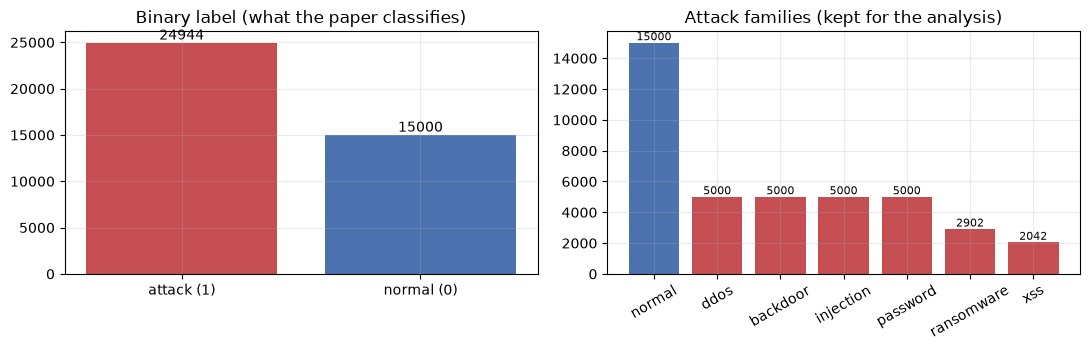

In [6]:
print("dataset shape        :", raw.shape)
print("feature columns      :", ["date", "time", "fridge_temperature", "temp_condition"], "(+ derived: ts_seconds, cond_clean)")
print("label values (0 normal, 1 attack):", raw["label"].value_counts().sort_index().to_dict())
print("attack family counts :", raw["type"].value_counts().to_dict())
print("temperature range    :", raw["fridge_temperature"].min(), "to", raw["fridge_temperature"].max(), "degrees C")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
cnt = raw["label"].map({0: "normal (0)", 1: "attack (1)"}).value_counts()
axes[0].bar(cnt.index, cnt.values, color=["#4c72b0", "#c44e52"][:len(cnt)] if cnt.index[0].startswith("normal") else ["#c44e52", "#4c72b0"])
axes[0].set_title("Binary label (what the paper classifies)")
for i, v in enumerate(cnt.values): axes[0].text(i, v, str(v), ha="center", va="bottom")
fam = raw["type"].value_counts()
axes[1].bar(fam.index, fam.values, color=["#4c72b0" if t == "normal" else "#c44e52" for t in fam.index])
axes[1].set_title("Attack families (kept for the analysis)")
axes[1].tick_params(axis="x", rotation=30)
for i, v in enumerate(fam.values): axes[1].text(i, v, str(v), ha="center", va="bottom", fontsize=8)
plt.tight_layout(); plt.show()

**The decisive finding.** Printing the *representation* of `temp_condition` per class shows that normal rows are
stored as `'high '`, `'high  '`, `'low '`, `'low  '` (one or two trailing blanks) while every attack row is `'high'` or
`'low'`. A text-to-number encoder that does not strip blanks therefore turns `temp_condition` into a perfect label
detector, and the temperature itself carries no information about the attack (its distribution is the same in every class, panel below).

Raw strings of temp_condition (repr) by attack family:


type,backdoor,ddos,injection,normal,password,ransomware,xss
temp_condition,,,,,,,
'high ',0,0,0,2373,0,0,0
'high ',0,0,0,6074,0,0,0
'high',2768,2847,2759,0,2818,1609,1138
'low ',0,0,0,1891,0,0,0
'low ',0,0,0,4662,0,0,0
'low',2232,2153,2241,0,2182,1293,904


share of attack rows whose text has NO trailing blank: 1.0
share of normal rows whose text HAS trailing blanks  : 1.0
stripped condition is a function of the temperature: low <= 5.95, high >= 6.0


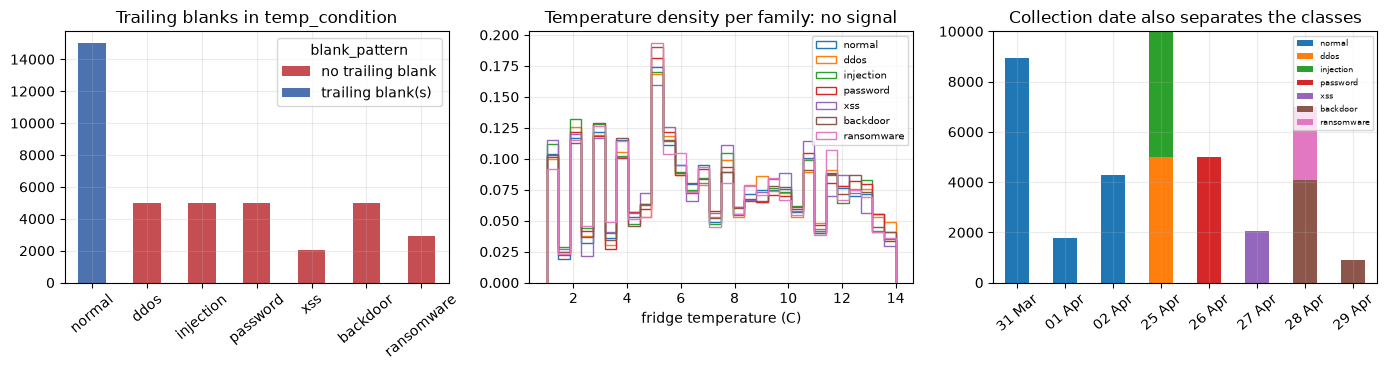

In [7]:
leak = pd.crosstab(raw["temp_condition"].map(repr), raw["type"])
print("Raw strings of temp_condition (repr) by attack family:")
display(leak)
print("share of attack rows whose text has NO trailing blank:", round(float(raw.loc[raw.label == 1, "temp_condition"].map(lambda s: s == s.strip()).mean()), 4))
print("share of normal rows whose text HAS trailing blanks  :", round(float(raw.loc[raw.label == 0, "temp_condition"].map(lambda s: s != s.strip()).mean()), 4))
lo_max = raw.loc[raw.cond_clean == 0, "fridge_temperature"].max(); hi_min = raw.loc[raw.cond_clean == 1, "fridge_temperature"].min()
print(f"stripped condition is a function of the temperature: low <= {lo_max}, high >= {hi_min}")

fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
order = ["normal", "ddos", "injection", "password", "xss", "backdoor", "ransomware"]
raw["blank_pattern"] = raw["temp_condition"].map(lambda s: "no trailing blank" if s == s.strip() else "trailing blank(s)")
tab = pd.crosstab(raw["type"], raw["blank_pattern"]).reindex(order)
tab.plot(kind="bar", stacked=True, ax=axes[0], color=["#c44e52", "#4c72b0"][:tab.shape[1]] if tab.columns[0] == "no trailing blank" else ["#4c72b0", "#c44e52"])
axes[0].set_title("Trailing blanks in temp_condition"); axes[0].set_xlabel(""); axes[0].tick_params(axis="x", rotation=40)
for t in order:
    v = raw.loc[raw.type == t, "fridge_temperature"]
    axes[1].hist(v, bins=30, histtype="step", density=True, label=t)
axes[1].set_title("Temperature density per family: no signal"); axes[1].set_xlabel("fridge temperature (C)"); axes[1].legend(fontsize=7)
by_day = pd.crosstab(raw["date"], raw["type"]).reindex(columns=order)
by_day.index = pd.to_datetime(by_day.index, format="%d-%b-%y")
by_day = by_day.sort_index(); by_day.index = by_day.index.strftime("%d %b")
by_day.plot(kind="bar", stacked=True, ax=axes[2], legend=True); axes[2].legend(fontsize=6)
axes[2].set_title("Collection date also separates the classes"); axes[2].set_xlabel("")
axes[2].tick_params(axis="x", rotation=40)
plt.tight_layout(); plt.show()

### Two-dimensional views of the real readings

The model inputs are two numbers per reading (temperature and the coded text), so a PCA of them is the faithful 2-D
picture of what the classifiers see. The PCA (after z-scoring) is fitted on a **training half** of the file and applied to
the other half, as the notebook's conventions require. The text is coded with the sorted list of the strings found
in the training half (`'high' < 'high ' < 'high  ' < 'low' < ...`), which is what a `LabelEncoder` would do. Points are
the real observations coloured by their family; the right-hand panels show each family alone, because the coded column takes
only six values and the points otherwise hide one another. There are no rotation angles in this paper, so the usual second
plot of angles scaled to $[0,\pi]$ does not apply; the next cell gives a window-feature projection of the time series instead.

code table (raw string -> code): {"'high'": 0, "'high '": 1, "'high  '": 2, "'low'": 3, "'low '": 4, "'low  '": 5}
PCA explained variance ratio: [0.881 0.119] | train points: 19972 | test points: 19972


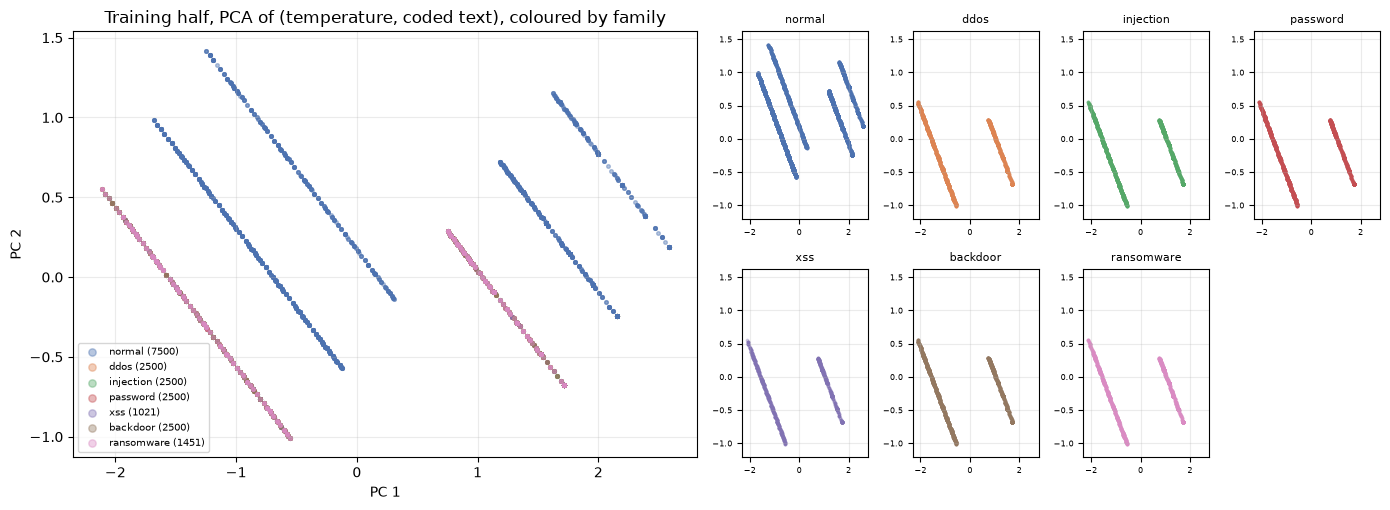

In [8]:
FAMILY_COLORS = {"normal": "#4c72b0", "ddos": "#dd8452", "injection": "#55a868", "password": "#c44e52", "xss": "#8172b3",
                 "backdoor": "#937860", "ransomware": "#da8bc3"}

def encode_condition(train_text, other_text):
    """Code the raw strings 0..5 by their sorted order in the TRAINING part; strings unseen in training get -1."""
    cats = sorted(pd.unique(train_text))
    table = {c: i for i, c in enumerate(cats)}
    return train_text.map(table).to_numpy(float), other_text.map(lambda s: table.get(s, -1)).to_numpy(float), table

expl_tr, expl_te = train_test_split(raw, test_size=0.5, stratify=raw["type"], random_state=SEED)
c_tr, c_te, code_table = encode_condition(expl_tr["temp_condition"], expl_te["temp_condition"])
print("code table (raw string -> code):", {repr(k): v for k, v in code_table.items()})
Ztr = np.c_[expl_tr["fridge_temperature"].to_numpy(float), c_tr]; Zte = np.c_[expl_te["fridge_temperature"].to_numpy(float), c_te]
sc_expl = StandardScaler().fit(Ztr)
pca_expl = PCA(n_components=2, random_state=SEED).fit(sc_expl.transform(Ztr))
P_tr = pca_expl.transform(sc_expl.transform(Ztr)); P_te = pca_expl.transform(sc_expl.transform(Zte))
print("PCA explained variance ratio:", np.round(pca_expl.explained_variance_ratio_, 3), "| train points:", len(P_tr), "| test points:", len(P_te))

fig = plt.figure(figsize=(14, 5.2))
gs = fig.add_gridspec(2, 6, width_ratios=[2.3, 2.3, 1, 1, 1, 1])
ax = fig.add_subplot(gs[:, 0:2])
idx = np.random.default_rng(SEED).permutation(len(P_tr))[:6000]
for t in order:
    m = (expl_tr["type"].to_numpy()[idx] == t)
    ax.scatter(P_tr[idx][m, 0], P_tr[idx][m, 1], s=7, alpha=0.4, color=FAMILY_COLORS[t], label=f"{t} ({int((expl_tr['type']==t).sum())})")
ax.set_title("Training half, PCA of (temperature, coded text), coloured by family"); ax.set_xlabel("PC 1"); ax.set_ylabel("PC 2"); ax.legend(fontsize=7, markerscale=2)
for k, t in enumerate(order):
    a = fig.add_subplot(gs[k // 4, 2 + k % 4])
    m = (expl_tr["type"].to_numpy() == t)
    a.scatter(P_tr[m, 0], P_tr[m, 1], s=3, alpha=0.3, color=FAMILY_COLORS[t]); a.set_title(t, fontsize=8)
    a.set_xlim(P_tr[:, 0].min() - 0.2, P_tr[:, 0].max() + 0.2); a.set_ylim(P_tr[:, 1].min() - 0.2, P_tr[:, 1].max() + 0.2); a.tick_params(labelsize=6)
plt.tight_layout(); plt.show()

windows: 399 | train windows: 199 | explained variance: [0.339 0.214]


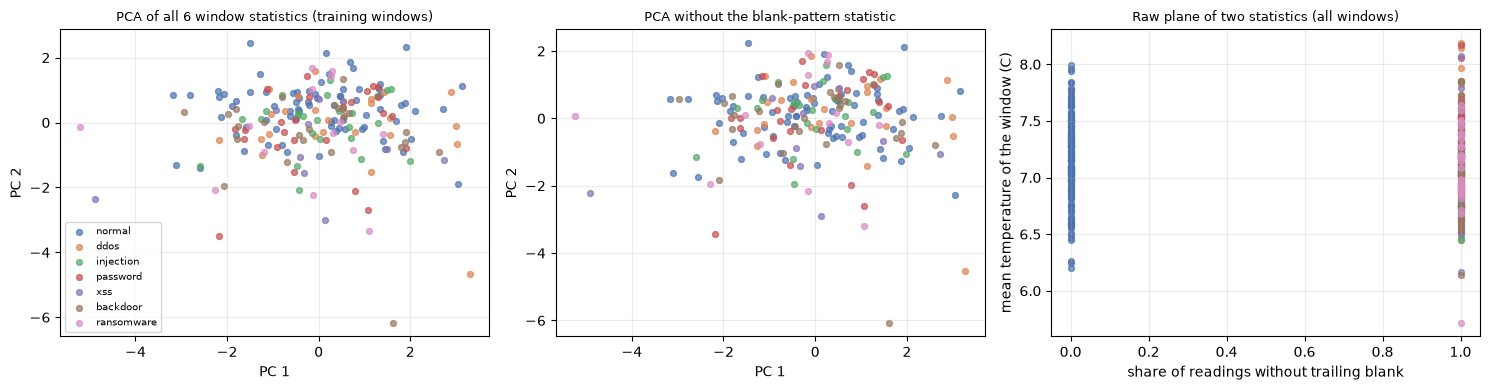

PCA keeps the directions of largest variance, and in these windows the five temperature statistics vary as much as the blank statistic,
so the two PCA panels look alike; the right-hand plane shows the one statistic that separates normal windows (0) from every attack family (1).


In [9]:
# Window-feature projection of the time series: 100 consecutive readings of one family -> 5 summary statistics -> PCA.
W = 100
rows = []
for t, g in raw.sort_values(["type", "ts_seconds"], kind="stable").groupby("type"):
    for s in range(0, len(g) - W + 1, W):
        w = g.iloc[s:s + W]
        rows.append(dict(type=t, mean_T=w.fridge_temperature.mean(), std_T=w.fridge_temperature.std(), min_T=w.fridge_temperature.min(),
                         max_T=w.fridge_temperature.max(), share_high=w.cond_clean.mean(),
                         share_blank_free=(w.temp_condition == w.temp_condition.str.strip()).mean()))
win = pd.DataFrame(rows)
wcols = ["mean_T", "std_T", "min_T", "max_T", "share_high", "share_blank_free"]
w_tr, w_te = train_test_split(win, test_size=0.5, stratify=win["type"], random_state=SEED)
sc_w = StandardScaler().fit(w_tr[wcols]); pca_w = PCA(n_components=2, random_state=SEED).fit(sc_w.transform(w_tr[wcols]))
Pw = pca_w.transform(sc_w.transform(w_tr[wcols]))
print("windows:", len(win), "| train windows:", len(w_tr), "| explained variance:", np.round(pca_w.explained_variance_ratio_, 3))
no_leak = ["mean_T", "std_T", "min_T", "max_T", "share_high"]
sc_n = StandardScaler().fit(w_tr[no_leak]); pca_n = PCA(n_components=2, random_state=SEED).fit(sc_n.transform(w_tr[no_leak]))
Pn = pca_n.transform(sc_n.transform(w_tr[no_leak]))
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for t in order:
    m = (w_tr["type"].to_numpy() == t)
    axes[0].scatter(Pw[m, 0], Pw[m, 1], s=18, alpha=0.7, color=FAMILY_COLORS[t], label=t)
    axes[1].scatter(Pn[m, 0], Pn[m, 1], s=18, alpha=0.7, color=FAMILY_COLORS[t])
    mm = (win["type"].to_numpy() == t)
    axes[2].scatter(win.loc[mm, "share_blank_free"], win.loc[mm, "mean_T"], s=18, alpha=0.7, color=FAMILY_COLORS[t])
axes[0].set_title("PCA of all 6 window statistics (training windows)", fontsize=9); axes[0].legend(fontsize=7); axes[0].set_xlabel("PC 1"); axes[0].set_ylabel("PC 2")
axes[1].set_title("PCA without the blank-pattern statistic", fontsize=9); axes[1].set_xlabel("PC 1"); axes[1].set_ylabel("PC 2")
axes[2].set_title("Raw plane of two statistics (all windows)", fontsize=9)
axes[2].set_xlabel("share of readings without trailing blank"); axes[2].set_ylabel("mean temperature of the window (C)")
plt.tight_layout(); plt.show()
print("PCA keeps the directions of largest variance, and in these windows the five temperature statistics vary as much as the blank statistic,")
print("so the two PCA panels look alike; the right-hand plane shows the one statistic that separates normal windows (0) from every attack family (1).")

## 2. Drawing the sample and building the inputs

Table 3 of the paper names each experiment by the number of attack and normal readings, e.g. `10,000, 300`. The function
`draw_sample(a, nn, seed)` draws exactly that many rows at random (`random_state = seed`), the drawn rows are split 50 : 50 into
a training part and a test part with stratification, and **all fitted quantities are computed from the training part only**:
the coding of the text column, the scaler of the SVC, the weak classifiers, the QUBO and the penalty $\lambda$.

Three input variants are used. `paper` is the reproduction proper: temperature plus the text of `temp_condition` coded
by sorted order (what scikit-learn's `LabelEncoder` does with the file as stored). `clean` strips the blanks first, so the
text becomes a 0/1 flag that is a function of the temperature. `stamp` adds the collection time stamp to the `paper` inputs.
The last two are ablations that expose what the first one measures.

In [10]:
SCENARIOS = {
    "paper": "temperature + text of temp_condition coded 0..5 (blanks kept, as stored)",
    "clean": "temperature + temp_condition stripped of blanks (0/1)",
    "stamp": "paper inputs + collection time stamp (seconds)",
}

def draw_sample(a, nn, seed):
    """a attack rows + nn normal rows at random; capped at what the public file holds."""
    A, N = raw[raw.label == 1], raw[raw.label == 0]
    df = pd.concat([A.sample(n=min(a, len(A)), random_state=seed), N.sample(n=min(nn, len(N)), random_state=seed)])
    return df.sample(frac=1.0, random_state=seed).reset_index(drop=True)

def make_features(tr, te, scenario):
    """Inputs for the three scenarios. Anything learned (the text coding) comes from the training part only."""
    if scenario == "clean":
        return (np.c_[tr.fridge_temperature, tr.cond_clean].astype(float), np.c_[te.fridge_temperature, te.cond_clean].astype(float),
                ["fridge_temperature", "cond_clean"])
    c_tr, c_te, _ = encode_condition(tr["temp_condition"], te["temp_condition"])
    Xtr, Xte = np.c_[tr.fridge_temperature, c_tr].astype(float), np.c_[te.fridge_temperature, c_te].astype(float)
    names = ["fridge_temperature", "condition_code"]
    if scenario == "stamp":
        Xtr, Xte = np.c_[Xtr, tr.ts_seconds], np.c_[Xte, te.ts_seconds]; names.append("ts_seconds")
    return Xtr, Xte, names

df_demo = draw_sample(1000, 1000, SEED)
tr_demo, te_demo = train_test_split(df_demo, test_size=TEST_SIZE, stratify=df_demo["label"], random_state=SEED)
for sc in SCENARIOS:
    Xa, Xb, nm = make_features(tr_demo, te_demo, sc)
    print(f"{sc:6s}: {SCENARIOS[sc]}\n        inputs {nm}, train {Xa.shape}, test {Xb.shape}, train classes {np.bincount(tr_demo.label)}")

paper : temperature + text of temp_condition coded 0..5 (blanks kept, as stored)
        inputs ['fridge_temperature', 'condition_code'], train (1000, 2), test (1000, 2), train classes [500 500]
clean : temperature + temp_condition stripped of blanks (0/1)
        inputs ['fridge_temperature', 'cond_clean'], train (1000, 2), test (1000, 2), train classes [500 500]
stamp : paper inputs + collection time stamp (seconds)
        inputs ['fridge_temperature', 'condition_code', 'ts_seconds'], train (1000, 3), test (1000, 3), train classes [500 500]


## 3. The pool of weak classifiers

Qboost needs a set of weak classifiers $h_1,\dots,h_K$ that each map a reading to $-1$ (normal) or $+1$ (attack). The D-Wave example the
paper uses builds them with AdaBoost: it trains `AdaBoostClassifier` and takes its single trees. We do the same with
depth-1 trees (decision stumps: "is feature $f$ below threshold $\theta$?"), $K = 20$. A stump is stored as four numbers
(feature, threshold, vote below, vote above), which lets the whole vote matrix $H_{si} = h_i(x_s)/K$ be computed in one numpy
expression; the cell asserts that this matrix equals the one obtained by calling every scikit-learn tree.

In [11]:
def fit_pool(X, y, seed, k=N_WEAK):
    stump = DecisionTreeClassifier(max_depth=1, random_state=seed)
    try:
        ada = AdaBoostClassifier(stump, n_estimators=k, algorithm="SAMME", random_state=seed)
    except TypeError:                                   # newer scikit-learn: SAMME is the only algorithm and the argument is gone
        ada = AdaBoostClassifier(stump, n_estimators=k, random_state=seed)
    return ada.fit(X, y)

def stump_table(estimators):
    feat, thr, left, right = [], [], [], []
    for e in estimators:
        t = e.tree_
        vote = lambda node: 2 * int(e.classes_[int(np.argmax(t.value[node]))]) - 1
        if t.feature[0] < 0:                            # degenerate tree: one leaf, constant vote
            feat.append(0); thr.append(np.inf); left.append(vote(0)); right.append(vote(0))
        else:
            feat.append(int(t.feature[0])); thr.append(float(t.threshold[0])); left.append(vote(1)); right.append(vote(2))
    return dict(feat=np.array(feat), thr=np.array(thr), left=np.array(left, float), right=np.array(right, float))

def stump_votes(tab, X):
    """n x K matrix of +-1 votes (tree rule: go left when x <= threshold, comparing in float32 like scikit-learn)."""
    return np.where(X.astype(np.float32)[:, tab["feat"]] <= tab["thr"], tab["left"], tab["right"])

Xa, Xb, _ = make_features(tr_demo, te_demo, "paper")
pool_demo = fit_pool(Xa, tr_demo.label.to_numpy(), SEED)
tab_demo = stump_table(pool_demo.estimators_)
K_demo = len(pool_demo.estimators_)
ref = np.column_stack([2 * e.predict(Xb.astype(np.float32)) - 1 for e in pool_demo.estimators_])
assert np.array_equal(stump_votes(tab_demo, Xb), ref), "vectorised stump votes differ from scikit-learn"
print(f"{K_demo} stumps; the vectorised vote matrix equals scikit-learn's predictions on {len(Xb)} test rows.")
print(pd.DataFrame({"feature": [["temperature", "condition_code"][f] for f in tab_demo["feat"]], "threshold": np.round(tab_demo["thr"], 2),
                    "vote if below": tab_demo["left"], "vote if above": tab_demo["right"]}).head(8).to_string())

20 stumps; the vectorised vote matrix equals scikit-learn's predictions on 1000 test rows.
          feature  threshold  vote if below  vote if above
0  condition_code       0.50            1.0           -1.0
1  condition_code       3.50            1.0           -1.0
2     temperature       6.03            1.0           -1.0
3  condition_code       0.50            1.0           -1.0
4  condition_code       3.50            1.0           -1.0
5     temperature       6.03            1.0           -1.0
6  condition_code       0.50            1.0           -1.0
7  condition_code       3.50            1.0           -1.0


## 4. From "which stumps vote?" to a QUBO, and two solvers

With binary weights $w\in\{0,1\}^K$, the Qboost objective of the paper's Section 4 is

$$ \mathcal L(w)=\frac1n\sum_s\Big(\sum_i w_i H_{si}-y_s\Big)^2+\lambda\sum_i w_i
 = w^\top\Big(\tfrac1n H^\top H+\mathrm{diag}\big(\lambda-\tfrac2n H^\top y\big)\Big)w+1 ,$$

using $w_i^2=w_i$ and $y_s^2=1$. The matrix in the middle is the **QUBO matrix** $Q$: its diagonal says how useful stump $i$ is on its own,
its off-diagonal entries how correlated two stumps are (correlated stumps repel each other), and $\lambda$ pays for every stump kept.
This is the matrix the D-Wave processor receives. The processor returns low-energy bit strings; the classifier votes with the stumps whose bit is 1.

Two solvers stand in for the annealer:

* `anneal_qubo`: a classical **simulated annealer** (single-bit-flip Metropolis moves, geometric cooling, 100 independent reads at once).
  The paper used the D-Wave sampler, which is also a heuristic sampler, so this is the same kind of tool.
* `exact_qubo`: enumeration of all $2^{20}\approx10^6$ bit strings. It is feasible only because $K=20$ and tells us whether the annealer found the true optimum.

QUBO energy + 1 equals the Qboost loss for 5 random weight vectors (assert passed).


K = 20 binary variables, 190 couplers | exact minimum -0.512440 (2.5 s) | best SA read -0.512440 (1.3 s) | reads that hit the optimum: 100/100


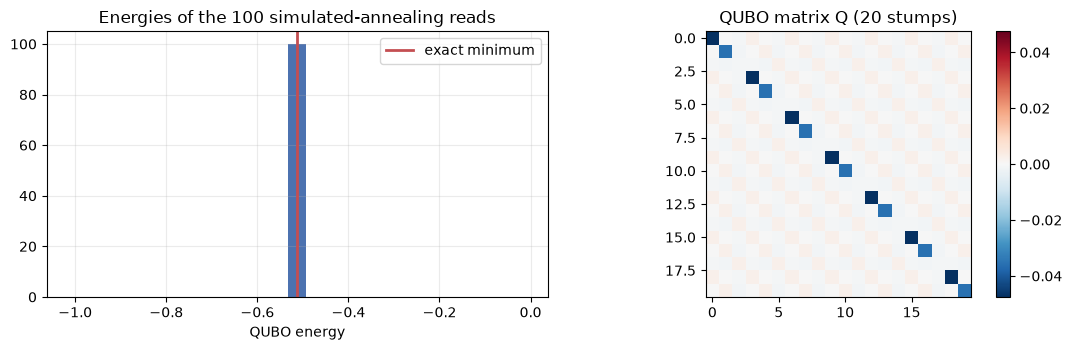

lambda = 0.0   : exact -0.572440  annealer -0.572440  gap 1.11e-16  selected stumps (exact) 20


lambda = 0.003 : exact -0.512440  annealer -0.512440  gap 8.88e-16  selected stumps (exact) 20


lambda = 0.03  : exact -0.067500  annealer -0.067500  gap 2.78e-17  selected stumps (exact) 7


In [12]:
def build_qubo(H, ypm, lam):
    """Q with  loss(w) = w^T Q w + 1  (ypm = labels in {-1,+1}, H = votes / K)."""
    n = H.shape[0]
    return H.T @ H / n + np.diag(lam - 2.0 * (H.T @ ypm) / n)

def anneal_qubo(Q, reads=None, sweeps=None, beta=None, seed=0):
    """Simulated annealing of E(x) = x^T Q x over x in {0,1}^K; returns (all read states, their energies)."""
    reads, sweeps, beta = reads or SA_READS, sweeps or SA_SWEEPS, beta or SA_BETA
    K = Q.shape[0]; r = np.random.default_rng(seed)
    S = (Q + Q.T) / 2.0; d = np.diag(S).copy(); O = S - np.diag(d)
    s = np.abs(S).max() or 1.0
    X = r.integers(0, 2, size=(reads, K)).astype(float)
    for b in np.geomspace(beta[0] / s, beta[1] / s, sweeps):
        for k in range(K):
            dE = (1.0 - 2.0 * X[:, k]) * (d[k] + 2.0 * (X @ O[:, k]))      # energy change if bit k flips
            flip = (dE <= 0) | (r.random(reads) < np.exp(-b * np.clip(dE, 0, None)))
            X[flip, k] = 1.0 - X[flip, k]
    return X, np.einsum("ri,ij,rj->r", X, Q, X)

def exact_qubo(Q, chunk=1 << 16):
    """Global minimum of x^T Q x by enumerating every bit string (K <= ~22)."""
    K = Q.shape[0]; S = (Q + Q.T) / 2.0; best_E, best_x = np.inf, None
    for start in range(0, 2 ** K, chunk):
        idx = np.arange(start, min(start + chunk, 2 ** K))
        X = ((idx[:, None] >> np.arange(K)) & 1).astype(float)
        E = ((X @ S) * X).sum(axis=1)
        j = int(np.argmin(E))
        if E[j] < best_E - 1e-15: best_E, best_x = float(E[j]), X[j].copy()
    return best_x, best_E

# --- check 1: the QUBO energy equals the Qboost loss for random weight vectors -------------------------------
Htr_demo = stump_votes(tab_demo, Xa) / K_demo
ypm_demo = 2.0 * tr_demo.label.to_numpy() - 1.0
Q_demo = build_qubo(Htr_demo, ypm_demo, 0.003)
for w in np.random.default_rng(SEED).integers(0, 2, size=(5, K_demo)).astype(float):
    loss = np.mean((Htr_demo @ w - ypm_demo) ** 2) + 0.003 * w.sum()
    assert abs(loss - (w @ Q_demo @ w + 1.0)) < 1e-9
print("QUBO energy + 1 equals the Qboost loss for 5 random weight vectors (assert passed).")

# --- check 2: simulated annealing against exact enumeration on three penalties -------------------------------
t0 = time.perf_counter(); X_sa, E_sa = anneal_qubo(Q_demo, seed=SEED); t_sa = time.perf_counter() - t0
t0 = time.perf_counter(); x_ex, E_ex = exact_qubo(Q_demo); t_ex = time.perf_counter() - t0
print(f"K = {K_demo} binary variables, {K_demo*(K_demo-1)//2} couplers | exact minimum {E_ex:.6f} ({t_ex:.1f} s) | best SA read {E_sa.min():.6f} ({t_sa:.1f} s)"
      f" | reads that hit the optimum: {int(np.sum(E_sa <= E_ex + 1e-9))}/{SA_READS}")
assert E_sa.min() <= E_ex + 1e-9
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].hist(E_sa, bins=25, color="#4c72b0"); axes[0].axvline(E_ex, color="#c44e52", lw=2, label="exact minimum")
axes[0].set_title("Energies of the 100 simulated-annealing reads"); axes[0].set_xlabel("QUBO energy"); axes[0].legend()
im = axes[1].imshow(Q_demo, cmap="RdBu_r", vmin=-np.abs(Q_demo).max(), vmax=np.abs(Q_demo).max())
axes[1].set_title("QUBO matrix Q (20 stumps)"); plt.colorbar(im, ax=axes[1]); axes[1].grid(False)
plt.tight_layout(); plt.show()
for lam in (0.0, 0.003, 0.03):
    Q = build_qubo(Htr_demo, ypm_demo, lam); _, e_sa = anneal_qubo(Q, seed=SEED); _, e_ex = exact_qubo(Q)
    print(f"lambda = {lam:<6}: exact {e_ex:+.6f}  annealer {e_sa.min():+.6f}  gap {e_sa.min()-e_ex:.2e}  selected stumps (exact) {int(exact_qubo(Q)[0].sum())}")

## Quantum Circuit Architecture

NOT_APPLICABLE: Qboost is a quantum-*annealing* method. The paper's quantum step hands a QUBO matrix to the D-Wave annealing
processor, which evolves a transverse-field Ising Hamiltonian continuously in time; there is no gate-based circuit, no
parametrised gates and no measurement circuit to draw. The only "architecture" is the QUBO itself: here 20 binary variables
(one per weak classifier) and 190 pairwise couplers (printed above, together with the heat-map of $Q$). The next section simulates the annealing
evolution exactly for a 10-variable QUBO, which is a Hamiltonian evolution, not a circuit.

## 5. What the annealer does: exact simulation of quantum annealing on a small QUBO

A D-Wave processor prepares every qubit in $|+\rangle$ and slowly changes the Hamiltonian from a "driver" to the "problem":

$$ H(s)= -(1-s)\,\Gamma\sum_k X_k + s\,\sum_{x}E(x)\,|x\rangle\langle x| ,\qquad s=t/T:\ 0\to1 ,$$

where $E(x)=x^\top Qx$ is the QUBO energy of the bit string $x$. If the sweep is slow enough, the adiabatic theorem keeps the
system in the lowest-energy state and a final measurement returns the optimal weights. For $K=10$ stumps the state has
$2^{10}$ amplitudes, so the Schrodinger equation can be integrated exactly on a laptop (Strang splitting; the driver acts qubit by qubit, the problem
Hamiltonian is diagonal). We use a real Qboost QUBO from 400 fridge readings, normalise the energies so that the problem term and the driver have the same
order of magnitude (`CHOICE`: $\Gamma=1$, energies scaled to $[-K/2, K/2]$), and measure the probability of finding a minimum-energy bit string as the annealing
time $T$ grows. This is an idealised, noise-free annealer; the real device adds noise, limited connectivity and a minor-embedding step (a 20-variable
fully connected QUBO needs chains of physical qubits).

QUBO with 10 variables (1024 bit strings), optimum -0.54700, number of optimal bit strings: 1


,T,steps,p_optimum,mean_energy,seconds
0,5,250,0.028591,-0.426450,0.7
1,20,850,0.218636,-0.508411,2.6
2,60,2450,0.567252,-0.538326,7.0
3,150,6050,0.789716,-0.543545,14.1


Trotter-step check at T = 20: P(optimum) = 0.2186 with 850 steps and 0.2186 with twice as many


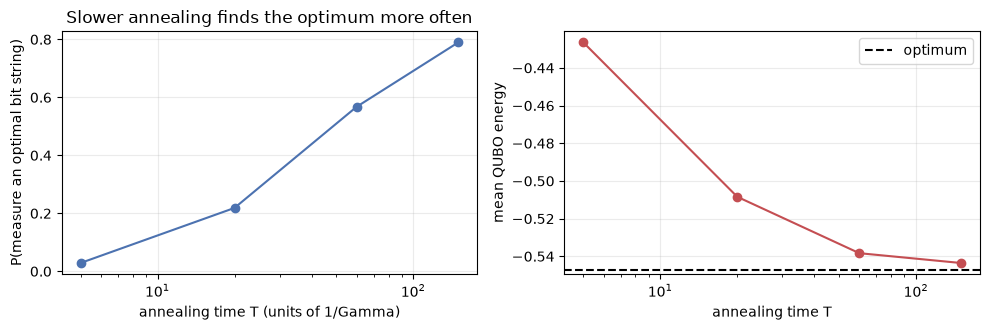

In [13]:
def qubo_energy_table(Q):
    K = Q.shape[0]; idx = np.arange(2 ** K)
    X = ((idx[:, None] >> np.arange(K)) & 1).astype(float)
    return ((X @ ((Q + Q.T) / 2.0)) * X).sum(axis=1)

def anneal_state(E, K, T, steps):
    """Final state of the annealing evolution H(s) = -(1-s) sum_k X_k + s * Ep(x), exact up to the Trotter step."""
    Ep = E / np.abs(E).max() * K / 2.0
    psi = np.full(2 ** K, 2.0 ** (-K / 2), dtype=complex)            # |+>^K, the ground state of the driver
    dt = T / steps
    for t in range(steps):
        s = (t + 0.5) / steps
        psi = psi * np.exp(-0.5j * dt * s * Ep)
        c, i_s = np.cos(dt * (1 - s)), 1j * np.sin(dt * (1 - s))     # exp(+i dt (1-s) X_k)
        psi = psi.reshape([2] * K)
        for ax in range(K):
            a, b = np.take(psi, 0, axis=ax), np.take(psi, 1, axis=ax)
            psi = np.stack([c * a + i_s * b, i_s * a + c * b], axis=ax)
        psi = psi.reshape(-1) * np.exp(-0.5j * dt * s * Ep)
    return psi

K_SQA, LAM_SQA = 10, 0.003                                          # CHOICE: 10 stumps -> 1024 amplitudes
df_s = draw_sample(200, 200, SEED)
Xs = make_features(df_s, df_s, "paper")[0]; ys = df_s.label.to_numpy()
pool_s = fit_pool(Xs, ys, SEED, k=K_SQA); tab_s = stump_table(pool_s.estimators_); K_s = len(pool_s.estimators_)
Q_s = build_qubo(stump_votes(tab_s, Xs) / K_s, 2.0 * ys - 1.0, LAM_SQA)
E_s = qubo_energy_table(Q_s); ground = E_s <= E_s.min() + 1e-9
print(f"QUBO with {K_s} variables ({2**K_s} bit strings), optimum {E_s.min():.5f}, number of optimal bit strings: {int(ground.sum())}")

T_LIST = [5, 20, 60, 150]
rows = []
for T in T_LIST:
    t0 = time.perf_counter(); psi = anneal_state(E_s, K_s, T, 40 * T + 50); p = np.abs(psi) ** 2
    assert abs(p.sum() - 1) < 1e-9                                  # unitary evolution keeps the norm
    rows.append(dict(T=T, steps=40 * T + 50, p_optimum=float(p[ground].sum()), mean_energy=float(p @ E_s), seconds=round(time.perf_counter() - t0, 1)))
sqa = pd.DataFrame(rows); display(sqa)
p_fine = float((np.abs(anneal_state(E_s, K_s, 20, 2 * (40 * 20 + 50))) ** 2)[ground].sum())
p_coarse = float(sqa.loc[sqa["T"] == 20, "p_optimum"].iloc[0])
print(f"Trotter-step check at T = 20: P(optimum) = {p_coarse:.4f} with {40*20+50} steps and {p_fine:.4f} with twice as many")
assert abs(p_fine - p_coarse) < 5e-3
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
ax[0].plot(sqa["T"], sqa["p_optimum"], "o-", color="#4c72b0"); ax[0].set_xscale("log"); ax[0].set_xlabel("annealing time T (units of 1/Gamma)")
ax[0].set_ylabel("P(measure an optimal bit string)"); ax[0].set_title("Slower annealing finds the optimum more often")
ax[1].plot(sqa["T"], sqa["mean_energy"], "o-", color="#c44e52"); ax[1].axhline(E_s.min(), color="k", ls="--", label="optimum"); ax[1].set_xscale("log")
ax[1].set_xlabel("annealing time T"); ax[1].set_ylabel("mean QUBO energy"); ax[1].legend(); plt.tight_layout(); plt.show()

## 6. The full Qboost pipeline and the baselines

`run_one(a, nn, seed, scenario)` is one row of the paper's Table 3 for one seed:

1. draw the sample, split 50 : 50, build the inputs (train-only coding);
2. **Qboost**: fit the AdaBoost pool of 20 stumps on the training half; for each penalty $\lambda$ in the grid anneal the QUBO built from 70 % of
   the training half and score the result on the other 30 %; keep the $\lambda$ with the best validation accuracy (ties to the larger,
   i.e. sparser); anneal the QUBO of the whole training half with that $\lambda$. The selected stumps vote, a tie goes to *normal*. After the timed part, the annealer's answer is checked
   against exact enumeration of all subsets (`sa_gap` is the energy difference, 0 means optimal);
3. **SVC**: `StandardScaler` (fitted on the training half) + `SVC()` with scikit-learn defaults - the paper's baseline;
4. **Random forest** (100 trees) and the **full AdaBoost** ensemble (all 20 stumps with their real-valued weights) on the same inputs, as extra references;
5. times: fit time, and prediction time on the test half (best of 5 repeats; for the SVC it includes the scaler).

In [14]:
def best_time(fn, repeats=TIMING_REPEATS):
    best, out = np.inf, None
    for _ in range(repeats):
        t0 = time.perf_counter(); out = fn(); best = min(best, time.perf_counter() - t0)
        if best > 1.0: break                                       # slow call: one measurement is enough
    return best, out

def metrics(y, p):
    return dict(acc=accuracy_score(y, p), prec=precision_score(y, p, zero_division=0), rec=recall_score(y, p, zero_division=0),
                f1=f1_score(y, p, zero_division=0))

def qboost_fit(H, ypm, y01, seed):
    """Lambda chosen on a validation part of the training sample; final QUBO solved on the whole training sample."""
    itr, iva = train_test_split(np.arange(len(y01)), test_size=VAL_FRACTION, stratify=y01, random_state=seed)
    best = None
    for lam in LAMBDA_GRID:
        X, E = anneal_qubo(build_qubo(H[itr], ypm[itr], lam), seed=seed)
        w = X[int(np.argmin(E))]
        if w.sum() == 0: continue                                  # the empty set predicts "normal" for everything
        acc = float(np.mean((H[iva] @ w > 0).astype(int) == y01[iva]))
        if best is None or acc >= best[0]: best = (acc, lam)       # ties -> larger lambda -> fewer stumps
    lam = best[1] if best else LAMBDA_GRID[0]
    Q = build_qubo(H, ypm, lam)
    X, E = anneal_qubo(Q, seed=seed + 1)
    w = X[int(np.argmin(E))]; fallback = False
    if w.sum() == 0:                                               # no subset beats the empty set: keep the single best stump
        w = np.zeros(H.shape[1]); w[int(np.argmax(H.T @ ypm))] = 1.0; fallback = True
    return w, lam, Q, float(E.min()), fallback

KEEP = {}      # predictions of the first seed, used for confusion matrices

def run_one(a, nn, seed, scenario, keep=False):
    df = draw_sample(a, nn, seed)
    tr, te = train_test_split(df, test_size=TEST_SIZE, stratify=df["label"], random_state=seed)
    Xtr, Xte, _ = make_features(tr, te, scenario)
    ytr, yte = tr.label.to_numpy(), te.label.to_numpy()
    out = dict(scenario=scenario, attack=a, normal=nn, seed=seed, n_train=len(tr), n_test=len(te),
               majority=max(np.mean(yte), 1 - np.mean(yte)))
    # ---------------- Qboost ----------------
    t0 = time.perf_counter()
    ada = fit_pool(Xtr, ytr, seed); tab = stump_table(ada.estimators_); K = len(tab["feat"])
    H = stump_votes(tab, Xtr) / K
    w, lam, Q, E_sa, fallback = qboost_fit(H, 2.0 * ytr - 1.0, ytr, seed)
    out["qb_fit_s"] = time.perf_counter() - t0
    sel = w > 0.5; tab_sel = {k: v[sel] for k, v in tab.items()}
    out["qb_pred_s"], p_qb = best_time(lambda: (stump_votes(tab_sel, Xte).sum(axis=1) > 0).astype(int))
    out.update({f"qb_{k}": v for k, v in metrics(yte, p_qb).items()})
    out.update(qb_lambda=lam, qb_nsel=int(sel.sum()), qb_K=K, qb_fallback=fallback)
    if K <= EXACT_MAX_VARS:
        _, E_ex = exact_qubo(Q); out["sa_gap"] = E_sa - E_ex
    else:
        out["sa_gap"] = np.nan
    # ---------------- SVC (paper's baseline) ----------------
    t0 = time.perf_counter(); scaler = StandardScaler().fit(Xtr); svc = SVC().fit(scaler.transform(Xtr), ytr); out["svc_fit_s"] = time.perf_counter() - t0
    out["svc_pred_s"], p_svc = best_time(lambda: svc.predict(scaler.transform(Xte)))
    out.update({f"svc_{k}": v for k, v in metrics(yte, p_svc).items()})
    # ---------------- extra references ----------------
    t0 = time.perf_counter(); rf = RandomForestClassifier(n_estimators=100, random_state=seed, n_jobs=1).fit(Xtr, ytr); out["rf_fit_s"] = time.perf_counter() - t0
    out["rf_pred_s"], p_rf = best_time(lambda: rf.predict(Xte)); out["rf_acc"] = accuracy_score(yte, p_rf)
    out["ada_pred_s"], p_ada = best_time(lambda: ada.predict(Xte)); out["ada_acc"] = accuracy_score(yte, p_ada)
    # per-family recall (detection rate of each attack family, specificity for normal)
    fam = te["type"].to_numpy()
    for t in np.unique(fam):
        m = fam == t
        out[f"qb_rec_{t}"] = float(np.mean(p_qb[m] == yte[m])); out[f"svc_rec_{t}"] = float(np.mean(p_svc[m] == yte[m]))
    if keep:
        KEEP[(scenario, a, nn, seed)] = dict(y=yte, qb=p_qb, svc=p_svc, fam=fam)
    return out

def run_grid(configs, seeds, scenario):
    rows, t_all = [], time.perf_counter()
    for (a, nn) in configs:
        for seed in seeds:
            t0 = time.perf_counter()
            r = run_one(a, nn, seed, scenario, keep=(seed == seeds[0]))
            rows.append(r)
            print(f"[{scenario}] {a:>6}/{nn:<6} seed {seed}: Qboost acc {r['qb_acc']:.3f} ({r['qb_nsel']} stumps, lambda {r['qb_lambda']}) | SVC acc {r['svc_acc']:.3f}"
                  f" | RF {r['rf_acc']:.3f} | SA gap {r['sa_gap']:.1e} | {time.perf_counter()-t0:.1f} s")
    print(f"[{scenario}] grid finished in {(time.perf_counter()-t_all)/60:.1f} min")
    return pd.DataFrame(rows)

# smoke test of the pipeline on the smallest paper row
_t = run_one(100, 100, SEED, "paper")
print({k: (round(v, 4) if isinstance(v, float) else v) for k, v in _t.items() if k in ("qb_acc", "svc_acc", "rf_acc", "qb_nsel", "qb_lambda", "sa_gap", "qb_pred_s", "svc_pred_s")})

{'qb_pred_s': 0.0, 'qb_acc': 0.99, 'qb_lambda': 0.01, 'qb_nsel': 18, 'sa_gap': -0.0, 'svc_pred_s': 0.0015, 'svc_acc': 0.96, 'rf_acc': 1.0}


## 7. Reproducing Table 3 (paper inputs)

Every row of the paper's Table 3 that the public file can supply is run with each seed. Rows with 55,000 or 60,000 readings per class are
impossible here (15,000 normal rows exist). In full mode one extra row uses everything the file holds. The summary shows the mean over seeds
with the standard deviation, the share of the majority class in the test half (the accuracy of a model that always answers the commoner class)
and the average number of stumps that Qboost keeps.

In [15]:
CONFIGS_RUN = list(MAIN_CONFIGS) + ([(24944, 15000)] if MAX_AVAILABLE_ROW else [])
res_paper = run_grid(CONFIGS_RUN, SEEDS, "paper")

def summarise(df):
    g = df.groupby(["attack", "normal"], sort=False)
    s = g.agg(runs=("seed", "count"), n_test=("n_test", "first"), majority=("majority", "mean"),
              qb_acc=("qb_acc", "mean"), qb_acc_sd=("qb_acc", "std"), svc_acc=("svc_acc", "mean"), svc_acc_sd=("svc_acc", "std"),
              rf_acc=("rf_acc", "mean"), ada_acc=("ada_acc", "mean"), qb_stumps=("qb_nsel", "mean"), qb_lambda=("qb_lambda", "median"),
              qb_pred_s=("qb_pred_s", "mean"), svc_pred_s=("svc_pred_s", "mean"), rf_pred_s=("rf_pred_s", "mean"),
              qb_fit_s=("qb_fit_s", "mean"), svc_fit_s=("svc_fit_s", "mean"), sa_gap_max=("sa_gap", "max")).reset_index()
    s["qb_acc_sd"] = s["qb_acc_sd"].fillna(0.0); s["svc_acc_sd"] = s["svc_acc_sd"].fillna(0.0)
    return s

sum_paper = summarise(res_paper)
show = sum_paper.copy()
show["Qboost acc"] = show.qb_acc.map("{:.3f}".format) + " +- " + show.qb_acc_sd.map("{:.3f}".format)
show["SVC acc"] = show.svc_acc.map("{:.3f}".format) + " +- " + show.svc_acc_sd.map("{:.3f}".format)
print(show[["attack", "normal", "runs", "n_test", "majority", "Qboost acc", "SVC acc", "rf_acc", "ada_acc", "qb_stumps", "qb_lambda"]].round(3).to_string(index=False))
print("\nAnnealer vs exact enumeration over all runs: largest energy gap =", f"{res_paper.sa_gap.max():.2e}",
      "| runs where the annealer was not optimal:", int((res_paper.sa_gap > 1e-9).sum()), "of", len(res_paper),
      "| runs that fell back to one stump:", int(res_paper.qb_fallback.sum()))

[paper]    100/100    seed 42: Qboost acc 0.990 (18 stumps, lambda 0.01) | SVC acc 0.960 | RF 1.000 | SA gap -4.4e-16 | 16.1 s


[paper]    100/100    seed 43: Qboost acc 0.990 (17 stumps, lambda 0.01) | SVC acc 1.000 | RF 0.990 | SA gap 7.2e-16 | 14.6 s


[paper]    100/100    seed 44: Qboost acc 1.000 (19 stumps, lambda 0.01) | SVC acc 1.000 | RF 1.000 | SA gap 2.2e-16 | 11.4 s


[paper]    100/100    seed 45: Qboost acc 0.980 (20 stumps, lambda 0.01) | SVC acc 0.990 | RF 0.990 | SA gap 1.7e-16 | 11.2 s


[paper]    100/100    seed 46: Qboost acc 1.000 (19 stumps, lambda 0.01) | SVC acc 0.980 | RF 1.000 | SA gap -3.3e-16 | 12.2 s


...

[paper]  24944/15000  seed 42: Qboost acc 1.000 (19 stumps, lambda 0.01) | SVC acc 1.000 | RF 1.000 | SA gap -1.1e-16 | 11.7 s


[paper]  24944/15000  seed 43: Qboost acc 1.000 (19 stumps, lambda 0.01) | SVC acc 1.000 | RF 1.000 | SA gap -3.3e-16 | 12.2 s


[paper]  24944/15000  seed 44: Qboost acc 1.000 (19 stumps, lambda 0.01) | SVC acc 1.000 | RF 1.000 | SA gap 1.2e-15 | 11.4 s


[paper]  24944/15000  seed 45: Qboost acc 1.000 (19 stumps, lambda 0.01) | SVC acc 1.000 | RF 1.000 | SA gap -1.4e-15 | 11.0 s


[paper]  24944/15000  seed 46: Qboost acc 1.000 (19 stumps, lambda 0.01) | SVC acc 1.000 | RF 1.000 | SA gap -2.8e-16 | 11.4 s
[paper] grid finished in 20.3 min
 attack  normal  runs  n_test  majority     Qboost acc        SVC acc  rf_acc  ada_acc  qb_stumps  qb_lambda
    100     100     5     100     0.500 0.992 +- 0.008 0.986 +- 0.017   0.996    0.992       18.6      0.010
    200     200     5     200     0.500 0.994 +- 0.007 0.997 +- 0.004   1.000    0.993       19.2      0.010
    300     300     5     300     0.500 0.999 +- 0.001 0.999 +- 0.001   1.000    0.999       19.0      0.010
    400     400     5     400     0.500 0.993 +- 0.005 1.000 +- 0.000   1.000    0.993       19.2      0.010
    400     500     5     450     0.556 0.997 +- 0.003 1.000 +- 0.000   0.998    0.997       19.4      0.010
    500     400     5     450     0.556 0.993 +- 0.009 1.000 +- 0.001   1.000    0.993       18.8      0.010
    500     500     5     500     0.500 0.998 +- 0.005 1.000 +- 0.000   1.00

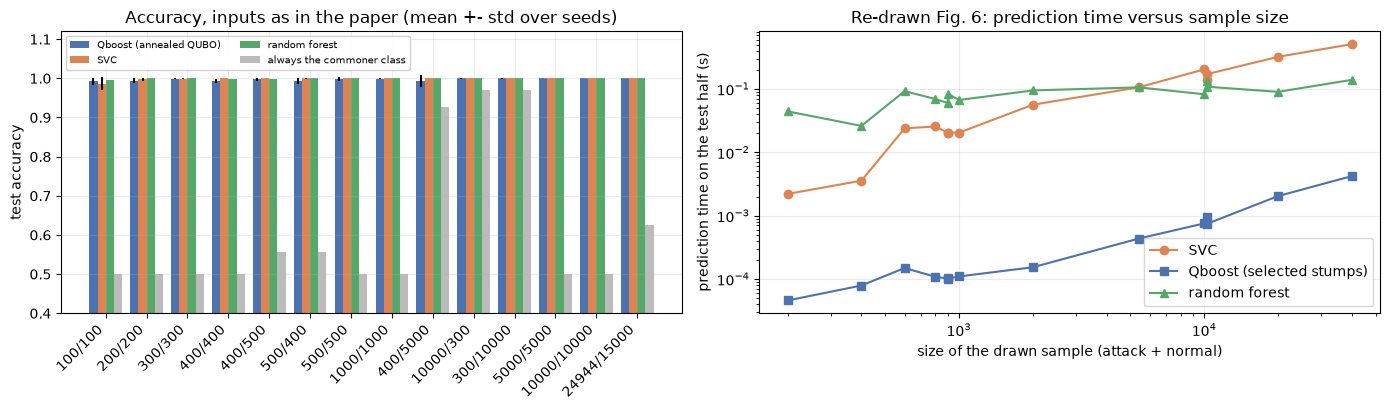

log-log slope of prediction time vs sample size (1 = linear): SVC 0.96 | Qboost 0.82 | random forest 0.20

Training (fit) time in seconds, mean over seeds. Qboost includes the AdaBoost pool, 8 annealing runs (7 penalties + final) and the vote selection:
 attack  normal  qb_fit_s  svc_fit_s
    100     100     9.309      0.018
    200     200     9.495      0.018
    300     300    21.700      0.046
    400     400    13.752      0.035
    400     500    13.440      0.029
    500     400    11.925      0.035
    500     500    12.932      0.029
   1000    1000    13.005      0.058
    400    5000    12.597      0.106
  10000     300    11.589      0.160
    300   10000    10.528      0.179
   5000    5000     7.936      0.163
  10000   10000     5.629      0.238
  24944   15000     4.846      0.347


In [16]:
# Figure A: accuracy per sample size.  Figure B (the paper's Fig. 6): prediction time against the number of examples.
labels = [f"{a}/{n}" for a, n in zip(sum_paper.attack, sum_paper.normal)]
x = np.arange(len(sum_paper)); wd = 0.2
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
ax[0].bar(x - 1.5 * wd, sum_paper.qb_acc, wd, yerr=sum_paper.qb_acc_sd, label="Qboost (annealed QUBO)", color="#4c72b0")
ax[0].bar(x - 0.5 * wd, sum_paper.svc_acc, wd, yerr=sum_paper.svc_acc_sd, label="SVC", color="#dd8452")
ax[0].bar(x + 0.5 * wd, sum_paper.rf_acc, wd, label="random forest", color="#55a868")
ax[0].bar(x + 1.5 * wd, sum_paper.majority, wd, label="always the commoner class", color="#bbbbbb")
ax[0].set_xticks(x); ax[0].set_xticklabels(labels, rotation=45, ha="right"); ax[0].set_ylim(0.4, 1.12); ax[0].set_ylabel("test accuracy")
ax[0].set_title("Accuracy, inputs as in the paper (mean +- std over seeds)"); ax[0].legend(fontsize=7, loc="upper left", ncol=2, framealpha=0.9)

n_drawn = (sum_paper.attack.clip(upper=24944) + sum_paper.normal.clip(upper=15000)).to_numpy()
order_idx = np.argsort(n_drawn)
ax[1].loglog(n_drawn[order_idx], sum_paper.svc_pred_s.to_numpy()[order_idx], "o-", color="#dd8452", label="SVC")
ax[1].loglog(n_drawn[order_idx], sum_paper.qb_pred_s.to_numpy()[order_idx], "s-", color="#4c72b0", label="Qboost (selected stumps)")
ax[1].loglog(n_drawn[order_idx], sum_paper.rf_pred_s.to_numpy()[order_idx], "^-", color="#55a868", label="random forest")
ax[1].set_xlabel("size of the drawn sample (attack + normal)"); ax[1].set_ylabel("prediction time on the test half (s)")
ax[1].set_title("Re-drawn Fig. 6: prediction time versus sample size"); ax[1].legend()
plt.tight_layout(); plt.show()

slope = lambda t: np.polyfit(np.log(n_drawn[order_idx]), np.log(np.maximum(t.to_numpy()[order_idx], 1e-9)), 1)[0]
alpha_svc, alpha_qb, alpha_rf = slope(sum_paper.svc_pred_s), slope(sum_paper.qb_pred_s), slope(sum_paper.rf_pred_s)
print(f"log-log slope of prediction time vs sample size (1 = linear): SVC {alpha_svc:.2f} | Qboost {alpha_qb:.2f} | random forest {alpha_rf:.2f}")
print("\nTraining (fit) time in seconds, mean over seeds. Qboost includes the AdaBoost pool, 8 annealing runs (7 penalties + final) and the vote selection:")
print(sum_paper[["attack", "normal", "qb_fit_s", "svc_fit_s"]].round(3).to_string(index=False))

Qboost, 10000 attacks / 10000 normal drawn, test half, seed 42  (the paper's Table 2 is the 10,000/10,000 row)
              precision    recall  f1-score   support

    0 normal       1.00      1.00      1.00      5000
    1 attack       1.00      1.00      1.00      5000

    accuracy                           1.00     10000
   macro avg       1.00      1.00      1.00     10000
weighted avg       1.00      1.00      1.00     10000



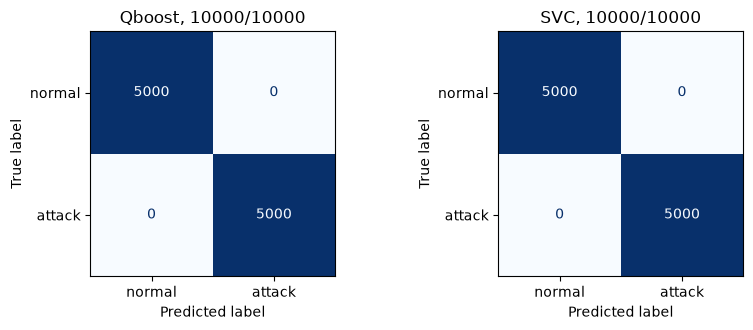


Per-family correct-classification rate, row 24944/15000, mean over seeds:


,normal,ddos,injection,password,xss,backdoor,ransomware
Qboost,1.0,1.0,1.0,1.0,1.0,1.0,1.0
SVC,1.0,1.0,1.0,1.0,1.0,1.0,1.0


In [17]:
# Table 2 of the paper: the confusion matrix / classification report of Qboost at the largest paper size we ran.
big = (10000, 10000) if (10000, 10000) in CONFIGS_RUN else (5000, 5000)
k = KEEP[("paper", big[0], big[1], SEEDS[0])]
print(f"Qboost, {big[0]} attacks / {big[1]} normal drawn, test half, seed {SEEDS[0]}  (the paper's Table 2 is the 10,000/10,000 row)")
print(classification_report(k["y"], k["qb"], target_names=["0 normal", "1 attack"], digits=2, zero_division=0))
fig, axes = plt.subplots(1, 2, figsize=(8.5, 3.4))
for ax_, key, ttl in zip(axes, ["qb", "svc"], ["Qboost", "SVC"]):
    ConfusionMatrixDisplay(confusion_matrix(k["y"], k[key], labels=[0, 1]), display_labels=["normal", "attack"]).plot(ax=ax_, colorbar=False, cmap="Blues")
    ax_.set_title(f"{ttl}, {big[0]}/{big[1]}"); ax_.grid(False)
plt.tight_layout(); plt.show()

# detection rate per attack family on the largest row we ran (recall of each family; for 'normal' the specificity)
fams = ["normal", "ddos", "injection", "password", "xss", "backdoor", "ransomware"]
last = res_paper[(res_paper.attack == CONFIGS_RUN[-1][0]) & (res_paper.normal == CONFIGS_RUN[-1][1])]
tab_f = pd.DataFrame({"Qboost": [last[f"qb_rec_{t}"].mean() if f"qb_rec_{t}" in last else np.nan for t in fams],
                      "SVC": [last[f"svc_rec_{t}"].mean() if f"svc_rec_{t}" in last else np.nan for t in fams]}, index=fams).round(3)
print(f"\nPer-family correct-classification rate, row {CONFIGS_RUN[-1][0]}/{CONFIGS_RUN[-1][1]}, mean over seeds:")
display(tab_f.T)

## 8. Ablation: what happens when the blanks are removed, and when time is allowed in

The inputs of Section 7 are the ones that reproduce the paper's pattern of accuracies. The same pipeline is now run on the two other input
variants of Section 2. With the blanks stripped, the only information left about the attack is the temperature, which the
exploration showed to be identically distributed in all classes. With the collection time stamp added, a model can read the day the data
was recorded, and normal and attack data were recorded on different days.

[clean]    100/100    seed 42: Qboost acc 0.500 (7 stumps, lambda 0.003) | SVC acc 0.510 | RF 0.520 | SA gap 6.9e-18 | 6.1 s


[clean]    100/100    seed 43: Qboost acc 0.490 (2 stumps, lambda 0.01) | SVC acc 0.460 | RF 0.430 | SA gap 0.0e+00 | 5.9 s


[clean]    100/100    seed 44: Qboost acc 0.500 (10 stumps, lambda 0.001) | SVC acc 0.490 | RF 0.550 | SA gap 0.0e+00 | 6.1 s


[clean]   1000/1000   seed 42: Qboost acc 0.515 (5 stumps, lambda 0.001) | SVC acc 0.510 | RF 0.516 | SA gap -8.7e-19 | 7.0 s


[clean]   1000/1000   seed 43: Qboost acc 0.509 (5 stumps, lambda 0.001) | SVC acc 0.517 | RF 0.526 | SA gap -8.7e-19 | 7.4 s


...

[stamp]   1000/1000   seed 43: Qboost acc 1.000 (1 stumps, lambda 0.1) | SVC acc 1.000 | RF 1.000 | SA gap 0.0e+00 | 0.6 s


[stamp]   1000/1000   seed 44: Qboost acc 1.000 (1 stumps, lambda 0.1) | SVC acc 1.000 | RF 1.000 | SA gap 0.0e+00 | 0.6 s


[stamp]  10000/10000  seed 42: Qboost acc 1.000 (1 stumps, lambda 0.1) | SVC acc 1.000 | RF 1.000 | SA gap 0.0e+00 | 1.1 s


[stamp]  10000/10000  seed 43: Qboost acc 1.000 (1 stumps, lambda 0.1) | SVC acc 1.000 | RF 1.000 | SA gap 0.0e+00 | 1.0 s


[stamp]  10000/10000  seed 44: Qboost acc 1.000 (1 stumps, lambda 0.1) | SVC acc 1.000 | RF 1.000 | SA gap 0.0e+00 | 1.0 s
[stamp] grid finished in 0.1 min
                 inputs  attack  normal  runs  majority  qb_acc  svc_acc  rf_acc  ada_acc  qb_stumps
    paper (blanks kept)     100     100     5     0.500   0.992    0.986   0.996    0.992     18.600
    paper (blanks kept)     200     200     5     0.500   0.994    0.997   1.000    0.993     19.200
    paper (blanks kept)     300     300     5     0.500   0.999    0.999   1.000    0.999     19.000
    paper (blanks kept)     400     400     5     0.500   0.993    1.000   1.000    0.993     19.200
    paper (blanks kept)     400     500     5     0.556   0.997    1.000   0.998    0.997     19.400
    paper (blanks kept)     500     400     5     0.556   0.993    1.000   1.000    0.993     18.800
    paper (blanks kept)     500     500     5     0.500   0.998    1.000   1.000    0.998     19.200
    paper (blanks kept)    1000    1

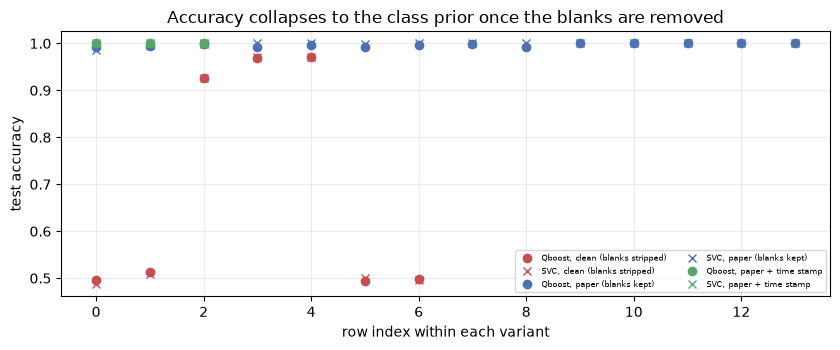

balanced rows (e.g. 1000/1000): clean-input accuracy of Qboost = [0.514] | SVC = [0.508] (chance = 0.5)


In [18]:
res_clean = run_grid(CLEAN_CONFIGS, CLEAN_SEEDS, "clean")
res_stamp = run_grid(TS_CONFIGS, TS_SEEDS, "stamp")
sum_clean, sum_stamp = summarise(res_clean), summarise(res_stamp)
abl = pd.concat([sum_paper.assign(inputs="paper (blanks kept)"), sum_clean.assign(inputs="clean (blanks stripped)"), sum_stamp.assign(inputs="paper + time stamp")])
print(abl[["inputs", "attack", "normal", "runs", "majority", "qb_acc", "svc_acc", "rf_acc", "ada_acc", "qb_stumps"]].round(3).to_string(index=False))

fig, ax = plt.subplots(figsize=(8.5, 3.6))
cols = {"paper (blanks kept)": "#4c72b0", "clean (blanks stripped)": "#c44e52", "paper + time stamp": "#55a868"}
for name, g in abl.groupby("inputs"):
    ax.plot(range(len(g)), g.qb_acc.to_numpy(), "o", color=cols[name], label=f"Qboost, {name}")
    ax.plot(range(len(g)), g.svc_acc.to_numpy(), "x", color=cols[name], label=f"SVC, {name}")
ax.set_xlabel("row index within each variant"); ax.set_ylabel("test accuracy"); ax.set_title("Accuracy collapses to the class prior once the blanks are removed")
ax.legend(fontsize=6, ncol=2); plt.tight_layout(); plt.show()
print("balanced rows (e.g. 1000/1000): clean-input accuracy of Qboost =", sum_clean[(sum_clean.attack == 1000) & (sum_clean.normal == 1000)].qb_acc.round(3).tolist(),
      "| SVC =", sum_clean[(sum_clean.attack == 1000) & (sum_clean.normal == 1000)].svc_acc.round(3).tolist(), "(chance = 0.5)")

## 9. Side by side with the paper, claim by claim

The paper's Table 3 is typed in below. A claim is **reproduced** when our mean accuracy is within 2 points of the paper's number, **exceeded** when it is
higher by more, **not reached** when it is lower by more, and **cannot be checked** when the public file cannot supply the experiment.
Absolute times in seconds depend on the machine (the paper does not name its hardware), so they are shown but not judged; the *ratios* and
the *direction* of the time claims are judged.

In [19]:
PAPER_TABLE3 = pd.DataFrame([
    (100, 100, 1.00, 1.00, 0.00059, 0.00043), (200, 200, 1.00, 1.00, 0.00066, 0.00037), (300, 300, 1.00, 1.00, 0.00039, 0.00082),
    (400, 400, 1.00, 1.00, 0.00099, 0.00044), (400, 500, 1.00, 1.00, 0.00106, 0.00039), (500, 400, 1.00, 1.00, 0.00125, 0.00052),
    (500, 500, 1.00, 1.00, 0.00111, 0.00042), (1000, 1000, 1.00, 1.00, 0.00181, 0.00044), (400, 5000, 1.00, 1.00, 0.00425, 0.00087),
    (10000, 300, 1.00, 0.80, 0.00803, 0.00125), (300, 10000, 1.00, 1.00, 0.00993, 0.00205), (5000, 5000, 1.00, 1.00, 0.00128, 0.00074),
    (10000, 10000, 1.00, 0.89, 0.02348, 0.00923), (55000, 55000, 0.25, 0.29, 0.05606, 0.01944), (60000, 60000, 0.23, 0.27, 0.05947, 0.01618)],
    columns=["attack", "normal", "svc_acc_paper", "qb_acc_paper", "svc_t_paper", "qb_t_paper"])

TOL = 0.02
def verdict(paper, ours, tol=TOL, available=True, run=True):
    if not available: return "cannot be checked (data)"
    if not run: return "not run (FAST_MODE)"
    d = ours - paper
    if abs(d) <= tol + 1e-12: return "reproduced"
    return f"exceeded (+{d:.2f})" if d > 0 else f"not reached ({d:.2f})"

cmp_ = PAPER_TABLE3.merge(sum_paper[["attack", "normal", "qb_acc", "svc_acc", "qb_pred_s", "svc_pred_s", "rf_acc"]], on=["attack", "normal"], how="left")
cmp_["available"] = (cmp_.attack <= 24944) & (cmp_.normal <= 15000)
rows = []
for _, r in cmp_.iterrows():
    ran = not np.isnan(r.qb_acc)
    rows.append({"attack/normal": f"{int(r.attack)}/{int(r.normal)}",
                 "SVC paper": r.svc_acc_paper, "SVC here": round(r.svc_acc, 3) if ran else np.nan, "SVC verdict": verdict(r.svc_acc_paper, r.svc_acc, available=r.available, run=ran),
                 "Qboost paper": r.qb_acc_paper, "Qboost here": round(r.qb_acc, 3) if ran else np.nan, "Qboost verdict": verdict(r.qb_acc_paper, r.qb_acc, available=r.available, run=ran),
                 "SVC t paper (s)": r.svc_t_paper, "SVC t here (s)": round(r.svc_pred_s, 5) if ran else np.nan,
                 "Qboost t paper (s)": r.qb_t_paper, "Qboost t here (s)": round(r.qb_pred_s, 5) if ran else np.nan})
claims = pd.DataFrame(rows)
print(claims.to_string(index=False))
acc_verdicts = pd.concat([claims["SVC verdict"], claims["Qboost verdict"]]).map(lambda v: v.split(" (")[0])
print("\nAccuracy verdicts over the 15 x 2 cells of Table 3 (SVC and Qboost columns):")
print(acc_verdicts.value_counts().to_string())

attack/normal  SVC paper  SVC here              SVC verdict  Qboost paper  Qboost here           Qboost verdict  SVC t paper (s)  SVC t here (s)  Qboost t paper (s)  Qboost t here (s)
      100/100       1.00     0.986               reproduced          1.00        0.992               reproduced          0.00059         0.00220             0.00043            0.00005
      200/200       1.00     0.997               reproduced          1.00        0.994               reproduced          0.00066         0.00356             0.00037            0.00008
      300/300       1.00     0.999               reproduced          1.00        0.999               reproduced          0.00039         0.02382             0.00082            0.00015
      400/400       1.00     1.000               reproduced          1.00        0.993               reproduced          0.00099         0.02550             0.00044            0.00011
      400/500       1.00     1.000               reproduced          1.00       

In [20]:
# Non-accuracy claims
final = []
def add(claim, paper, ours, verdict_):
    final.append({"claim": claim, "paper": paper, "this notebook": ours, "verdict": verdict_})

ran = cmp_[~cmp_.qb_acc.isna()]
# (a) table-level accuracy statements
n_equal = int(((ran.qb_acc - ran.svc_acc).abs() <= TOL).sum())
add("Table 3 accuracy: Qboost and SVC are 'equivalent' except for 10,000/300 and 10,000/10,000", "equivalent in 11 of 13 feasible rows",
    f"|Qboost - SVC| <= 0.02 in {n_equal} of {len(ran)} rows run", "reproduced" if n_equal >= len(ran) - 2 else "not reached")
# (b) Table 2 confusion matrix at 10,000/10,000
if (10000, 10000) in CONFIGS_RUN:
    rep = classification_report(k["y"], k["qb"], output_dict=True, zero_division=0)
    ours = f"acc {rep['accuracy']:.2f}; normal P/R {rep['0']['precision']:.2f}/{rep['0']['recall']:.2f}; attack P/R {rep['1']['precision']:.2f}/{rep['1']['recall']:.2f}"
    add("Table 2: Qboost at 10,000/10,000 has accuracy 0.89 (normal P 0.82 R 1.00, attack P 1.00 R 0.78)", "acc 0.89", ours, verdict(0.89, rep["accuracy"]))
else:
    add("Table 2: Qboost at 10,000/10,000 has accuracy 0.89", "acc 0.89", "row not run in FAST_MODE", "not run (FAST_MODE)")
add("Table 3: accuracy collapses to 0.25-0.29 at 55,000/55,000 and 0.23-0.27 at 60,000/60,000", "0.23-0.29", "file holds only 15,000 normal rows", "cannot be checked (data)")
add("Abstract: Qboost improves detection accuracy (higher than SVC at the two largest sizes)", "0.29 vs 0.25 and 0.27 vs 0.23", "largest size available shows no accuracy gap" if abs(ran.iloc[-1].qb_acc - ran.iloc[-1].svc_acc) < TOL else "gap present",
    "cannot be checked (data)")
# (c) time claims
faster = int((ran.qb_pred_s < ran.svc_pred_s).sum())
add("Qboost prediction is faster than SVC in 14 of 15 rows", "14 of 15", f"{faster} of {len(ran)} rows run", "reproduced" if faster >= 0.75 * len(ran) else "not reached")
red_paper = float(((PAPER_TABLE3.svc_t_paper - PAPER_TABLE3.qb_t_paper) / PAPER_TABLE3.svc_t_paper).mean() * 100)
red_ours = float(((ran.svc_pred_s - ran.qb_pred_s) / ran.svc_pred_s).mean() * 100)
v_red = "reproduced" if abs(red_ours - 33.73) <= 10 else (f"exceeded (+{red_ours-33.73:.1f} points)" if red_ours > 33.73 else f"not reached ({red_ours-33.73:.1f} points)")
add("Qboost lowers the classification time by 33.73 % (tolerance +-10 points, CHOICE)", f"33.73 % stated; {red_paper:.1f} % recomputed from the paper's Table 3", f"mean reduction over rows run: {red_ours:.1f} %", v_red)
r500 = ran[(ran.attack == 500) & (ran.normal == 500)]
if len(r500):
    add("Time of Qboost / time of SVC at 500/500 (0.00042 s / 0.00111 s)", f"{0.00042/0.00111:.2f}", f"{(r500.qb_pred_s/r500.svc_pred_s).iloc[0]:.2f}",
        "reproduced" if abs((r500.qb_pred_s/r500.svc_pred_s).iloc[0] - 0.00042/0.00111) <= 0.15 else "not reached (ratio differs by > 0.15)")
else:
    add("Time of Qboost / time of SVC at 500/500 (0.00042 s / 0.00111 s)", f"{0.00042/0.00111:.2f}", "row 500/500 not run", "not run (FAST_MODE)")
add("Fig. 6: SVC time grows 'similar to exponential', Qboost 'similar to logarithmic' (slower growth)", "SVC grows faster than Qboost",
    f"log-log slopes: SVC {alpha_svc:.2f}, Qboost {alpha_qb:.2f}", "reproduced" if alpha_qb < alpha_svc - 0.1 else "not reached (Qboost does not grow more slowly)")
add("Absolute times in seconds (Table 3, columns 4-5)", "e.g. 0.00059 / 0.00043 s at 100/100", "machine dependent, see table above", "cannot be checked (hardware)")
final = pd.DataFrame(final)
print(final.to_string(index=False))
allv = pd.concat([acc_verdicts, final["verdict"].map(lambda v: v.split(" (")[0])])
print("\nAll verdicts (Table 3 accuracy cells + other claims):")
print(allv.value_counts().to_string())

                                                                                           claim                                                      paper                                        this notebook                               verdict
       Table 3 accuracy: Qboost and SVC are 'equivalent' except for 10,000/300 and 10,000/10,000                       equivalent in 11 of 13 feasible rows          |Qboost - SVC| <= 0.02 in 13 of 13 rows run                            reproduced
 Table 2: Qboost at 10,000/10,000 has accuracy 0.89 (normal P 0.82 R 1.00, attack P 1.00 R 0.78)                                                   acc 0.89 acc 1.00; normal P/R 1.00/1.00; attack P/R 1.00/1.00                      exceeded (+0.11)
        Table 3: accuracy collapses to 0.25-0.29 at 55,000/55,000 and 0.23-0.27 at 60,000/60,000                                                  0.23-0.29                   file holds only 15,000 normal rows              cannot be checked (data)
         Abs

## 10. Reading the paper critically

**1. The 1.00 accuracy comes from how the file stores a text column, not from detecting attacks.** In the data every attack row
stores `temp_condition` as `'high'` or `'low'` and every normal row as `'high '`, `'high  '`, `'low '` or `'low  '` (Dataset Exploration, third
figure and the `repr` table). A text encoder that keeps the blanks turns that column into a perfect label. The fridge temperature itself has
the same distribution in all seven classes (middle panel), and the six attack families sit on top of one another in every projection of the real readings.
When the blanks are stripped (Section 8) Qboost, the SVC and a random forest all fall to the class prior (chance on balanced rows, the majority share on unbalanced rows), and when the collection time stamp
is added a single stump suffices because normal and attack data were recorded on different days. A fridge thermometer has no physical reason to reveal a network attack; the paper's "high-performance intrusion detection" is therefore not
evidence that annealing detects intrusions. The ToN_IoT network-traffic files would be the realistic test.

**2. The accuracy drops of the paper are not reproduced and are not explained.** With the paper's inputs our Qboost keeps the accuracy of the SVC at every sample size the file can supply,
including the rows (10,000/300 and 10,000/10,000) where the paper reports 0.80 and 0.89, and the 55,000/60,000 rows cannot be run because the public file has only 15,000 normal readings.
An accuracy of 0.23-0.29 on balanced binary data is *below* chance, which means the predictions are systematically wrong, something a correct train/test pipeline does not produce. The paper does not give
the number of weak classifiers, the penalty, the annealing parameters, the encoding of the text column or the split, so the cause (a noisy hybrid solver call, a different pool, a misaligned label vector at
large size) cannot be identified from the text.

**3. No quantum advantage is measured, and none is needed.** The QUBO has 20 binary variables. Exact enumeration of all $2^{20}$ subsets takes about two seconds on a laptop, and the simulated annealer found
the global optimum in 69 of the 70 runs of Section 7 (the one miss is 1.3e-4 in energy, and the ablation runs show misses of at most 8e-4; the energies are printed in each run line). The "classification time" the paper compares is the time to *apply* the finished model, i.e. a few threshold comparisons, which is ordinary classical
computation after the annealer has returned; the annealing call, the cloud queue and the minor embedding are not in the timing, and our fit-time table shows that training Qboost is slower than training the SVC.
The speed-up in prediction comes from the model being small (a handful of stumps against an SVC with many support vectors), a property one also gets from a greedy or L1-penalised classical selection.

**4. The time claims depend on the implementation and are not internally consistent.** Our Qboost prediction is one vectorised numpy comparison, the SVC prediction is libsvm plus a scaler; the ratio we measure differs
by far from the paper's 0.38 at 500/500, and absolute seconds depend on the machine. The paper's "33.73 %" does not match its own Table 3 (the mean per-row reduction recomputed from the table is printed in Section 9), and its "0.00042 s
per 1000 examples" is simply the value of the 500/500 row. The statements "exponential" for the SVC and "logarithmic" for Qboost are drawn from 15 single timings of 0.0004-0.06 s, at the level of timer noise for the small rows; our log-log slopes (Section 7) show roughly linear to sub-linear growth for both, not an
exponential.

**5. Protocol gaps.** One run per row, no seeds, no confidence intervals, an unspecified train/test split, no mention of the 2,834 duplicated readings, no hardware description, and a dataset described as
587,077 rows while the only freely mirrored version of the Fridge file is the 39,944-row official train/test subset. The conclusion that quantum classification is "effective" is therefore not supported by the experiment as reported; what *is* supported (and reproduced here) is that a Qboost ensemble of stumps matches an SVC on this file and predicts faster, which is a statement about a trivially separable file and a small model.

## 11. Exercises

1. **Strip the blanks yourself.** In `make_features` the scenario `clean` removes the trailing blanks. Re-run Section 7 with `clean` as the main
   scenario and explain, using the density panel of the exploration, why the accuracy of every model approaches the class prior. What would a model
   need in order to detect these attacks from the fridge telemetry alone?
2. **One-hot instead of integer codes.** Replace the 0..5 coding of `temp_condition` with one-hot columns (`pd.get_dummies`). How many stumps does Qboost
   now need to reach 100 % accuracy, and does the optimal `lambda` change?
3. **Annealer quality.** Reduce `SA_SWEEPS` to 20 and `SA_READS` to 5 and count in how many runs the annealer misses the exact optimum (`sa_gap`).
   Does a worse optimiser change the accuracy? What does that say about the value of a *quantum* annealer for a 20-variable problem?
4. **Bigger pools.** Set `N_WEAK = 30` and `EXACT_MAX_VARS = 22` (so exact enumeration is skipped). How do the fit time and the number of selected
   stumps change? Why does the fit time, which the paper does not report, grow much faster than the prediction time?
5. **Annealing time.** In Section 5 try `LAM_SQA = 0.0` and `0.03` and plot the probability of the optimum against `T`. Which problem is harder for the
   annealer, and how does that relate to the minimum energy gap of the Hamiltonian along the schedule?